In [1]:
# =========================================================
# Sleep Behavior Pattern Analysis using Unsupervised Learning
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
import os

os.makedirs("../images", exist_ok=True)
os.makedirs("../data", exist_ok=True)

In [3]:
# =========================================================
# Load analyzed session-level dataset
# =========================================================

df = pd.read_csv("analyzed_sessions.csv")

print(f"Initial sessions: {len(df)}")
print(df.head())

Initial sessions: 223
               session_id  sleep_quality_score  sound_std  motion_rate  \
0  sleep_20260401_user001            98.486045   0.081756     0.171569   
1  sleep_20260401_user001            96.473595   0.003571     0.000000   
2  sleep_20260401_user001            89.383007   0.002482     0.000000   
3  sleep_20260401_user001            90.216710   0.003640     0.000000   
4  sleep_20260401_user001            91.062277   0.005986     0.011136   

   light_avg  temp_std  humidity_std  
0   0.022889  0.161992      0.110210  
1   0.022183  0.132625      0.234483  
2   0.009126  0.101669      0.222169  
3   0.005848  0.094388      0.235115  
4   0.005848  0.108229      0.275411  


In [4]:
# =========================================================
# Remove missing or invalid data
# =========================================================

df = df.dropna()

print(f"After cleaning: {len(df)} sessions")

After cleaning: 223 sessions


In [5]:
# =========================================================
# Select relevant features for clustering
# =========================================================

features = [
    'sound_std',
    'motion_rate',
    'light_avg',
    'temp_std',
    'humidity_std'
]

X = df[features].values

print("Selected features:", features)

Selected features: ['sound_std', 'motion_rate', 'light_avg', 'temp_std', 'humidity_std']


In [6]:
# =========================================================
# Normalize features for clustering
# =========================================================

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature scaling complete.")

Feature scaling complete.


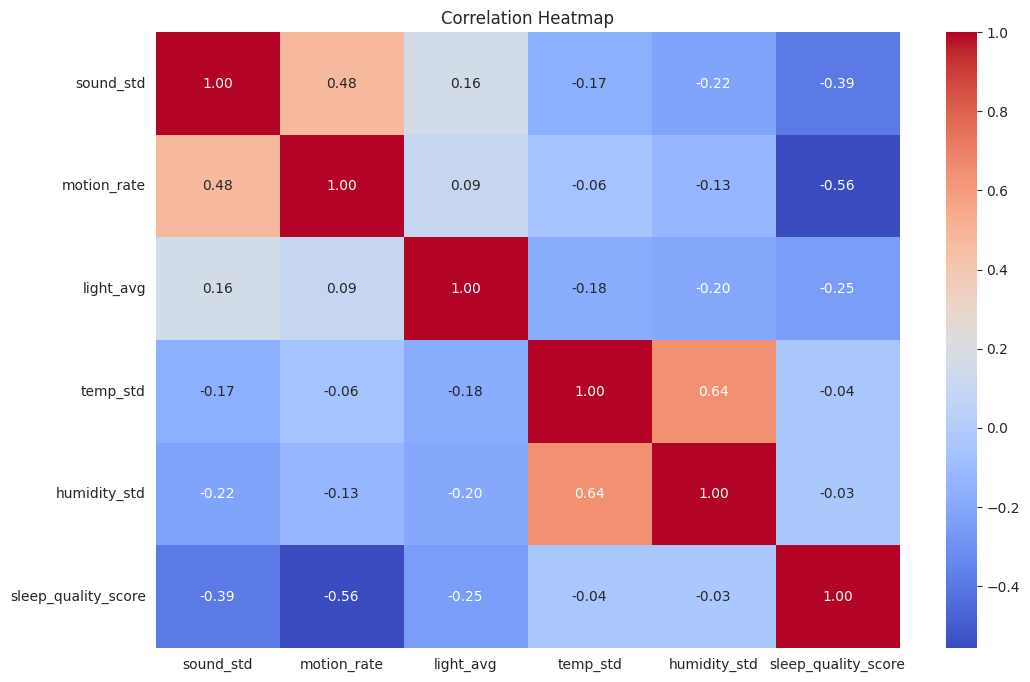

In [7]:
# =========================================================
# Correlation analysis between variables
# =========================================================

corr = df[features + ['sleep_quality_score']].corr()

plt.figure()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.savefig("../images/correlation_heatmap.png", dpi=300)
plt.show()

In [8]:
# =========================================================
# Generate rule-based insights for UI
# =========================================================

def generate_insights(corr):
    insights = []

    if corr["light_avg"]["sleep_quality_score"] < -0.4:
        insights.append("Lower light exposure is associated with better sleep quality.")

    if corr["sound_std"]["sleep_quality_score"] < -0.4:
        insights.append("Lower noise variability improves sleep stability.")

    if corr["motion_rate"]["sleep_quality_score"] < -0.4:
        insights.append("Higher movement during sleep is linked to disturbances.")

    if corr["temp_std"]["sleep_quality_score"] < -0.3:
        insights.append("Stable temperature conditions support better sleep.")

    if corr["humidity_std"]["sleep_quality_score"] < -0.3:
        insights.append("Consistent humidity contributes to improved sleep comfort.")

    return insights


insights = generate_insights(corr)

print("\nRule-Based Insights:")
for i in insights:
    print("-", i)


Rule-Based Insights:
- Higher movement during sleep is linked to disturbances.


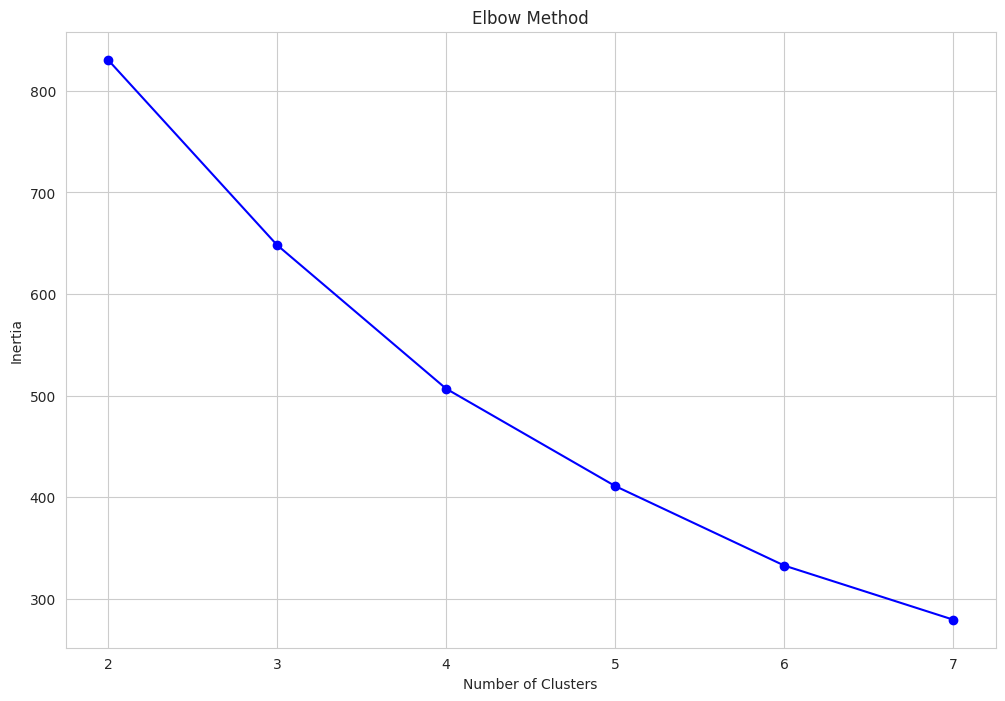

In [9]:
# =========================================================
# Determine optimal number of clusters
# =========================================================

inertias = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.plot(K_range, inertias, 'bo-')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.savefig("../images/elbow_plot.png", dpi=300)
plt.show()

k=2: Silhouette Score = 0.292
k=3: Silhouette Score = 0.332
k=4: Silhouette Score = 0.370
k=5: Silhouette Score = 0.396
k=6: Silhouette Score = 0.426
k=7: Silhouette Score = 0.433


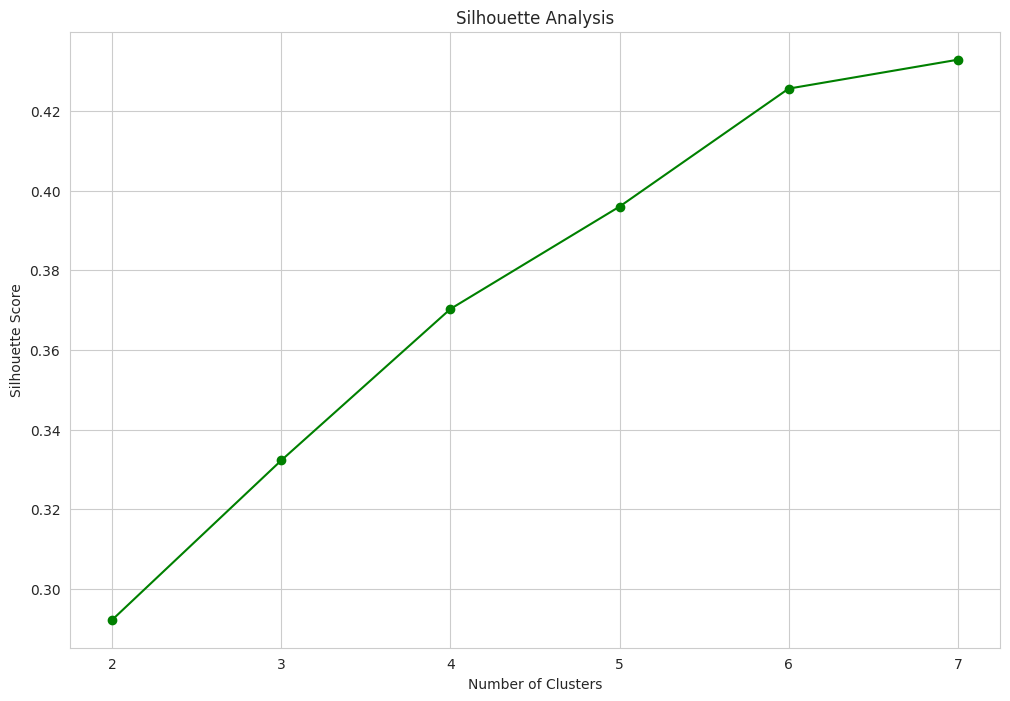

In [10]:
# =========================================================
# Evaluate clustering quality
# =========================================================

silhouette_scores = []

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k={k}: Silhouette Score = {score:.3f}")

plt.plot(K_range, silhouette_scores, 'go-')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Analysis')
plt.savefig("../images/silhouette_plot.png", dpi=300)
plt.show()

In [11]:
# =========================================================
# Apply K-Means clustering
# =========================================================

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X_scaled)

print("Cluster distribution:")
print(df['cluster'].value_counts())

Cluster distribution:
cluster
2    94
0    75
1    54
Name: count, dtype: int64


In [12]:
# =========================================================
# Analyze cluster characteristics
# =========================================================

cluster_summary = df.groupby('cluster')[features + ['sleep_quality_score']].mean()

print("\nCluster Summary:")
print(cluster_summary)


Cluster Summary:
         sound_std  motion_rate  light_avg  temp_std  humidity_std  \
cluster                                                              
0         0.027434     0.055824   0.017519  0.211620      0.295736   
1         0.168024     0.523547   0.151433  0.049482      0.063215   
2         0.052518     0.050852   0.153236  0.026375      0.039445   

         sleep_quality_score  
cluster                       
0                  93.866934  
1                  88.296081  
2                  93.741270  


In [13]:
# =========================================================
# Assign cluster names based on sleep quality
# =========================================================

sorted_clusters = cluster_summary['sleep_quality_score'].sort_values(ascending=False)

cluster_names = {
    sorted_clusters.index[0]: 'Good Sleep',
    sorted_clusters.index[1]: 'Light Sleep',
    sorted_clusters.index[2]: 'Disturbed Sleep'
}

df['cluster_name'] = df['cluster'].map(cluster_names)

print("\nCluster labels assigned:")
print(cluster_names)


Cluster labels assigned:
{np.int32(0): 'Good Sleep', np.int32(2): 'Light Sleep', np.int32(1): 'Disturbed Sleep'}


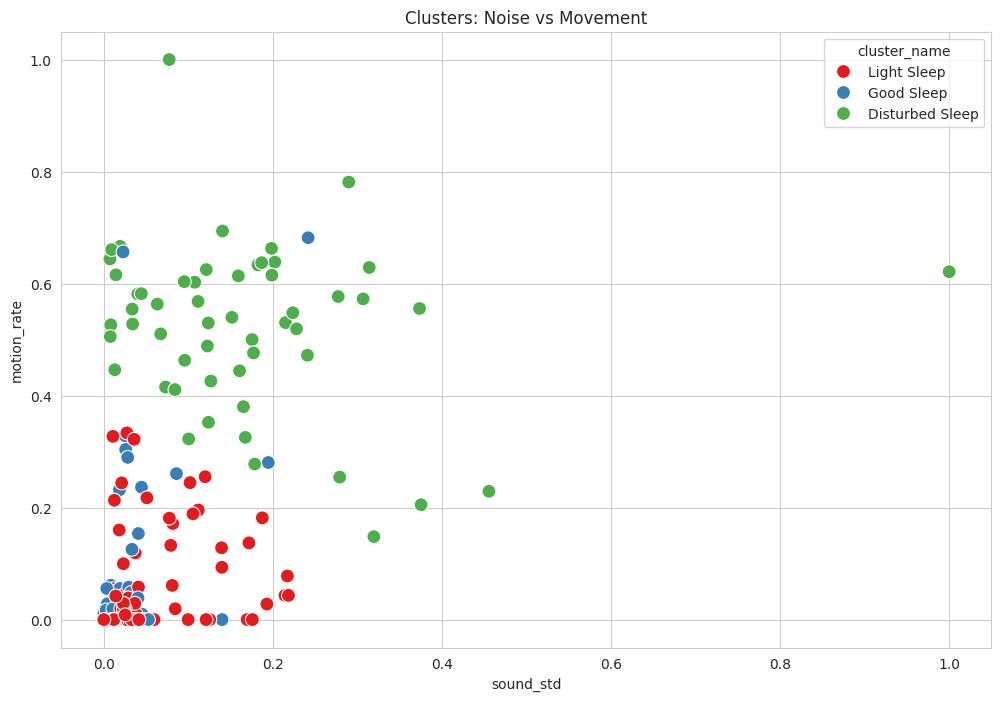

In [14]:
# =========================================================
# Visualize clusters
# =========================================================

sns.scatterplot(
    data=df,
    x='sound_std',
    y='motion_rate',
    hue='cluster_name',
    palette='Set1',
    s=100
)

plt.title("Clusters: Noise vs Movement")
plt.savefig("../images/cluster_scatter.png", dpi=300)
plt.show()

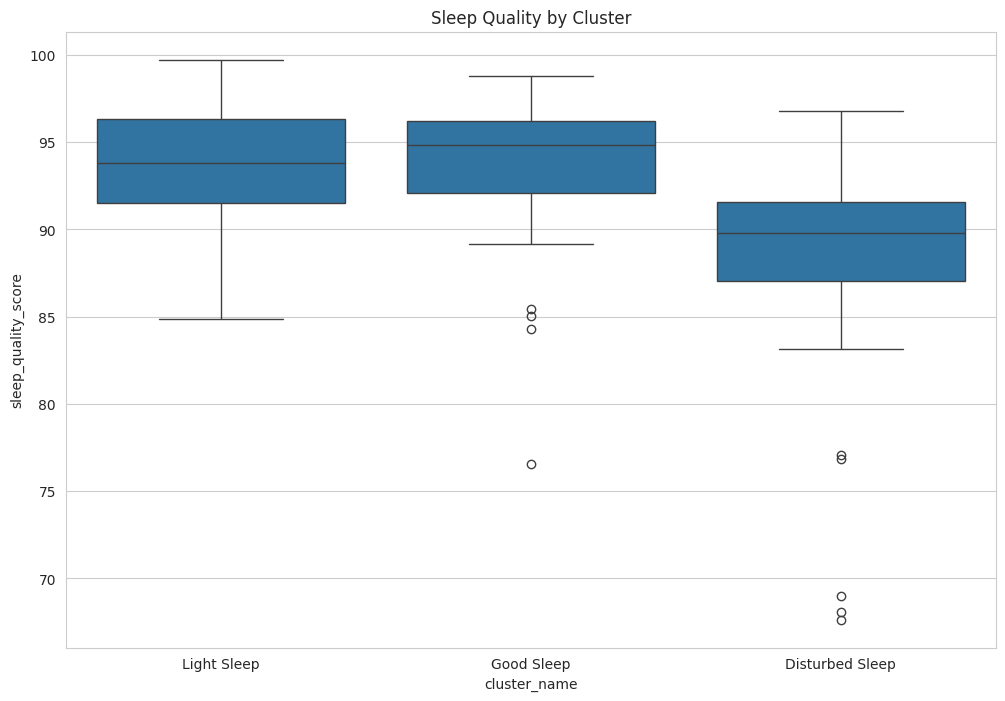

In [15]:
# =========================================================
# Sleep quality distribution per cluster
# =========================================================

sns.boxplot(
    data=df,
    x='cluster_name',
    y='sleep_quality_score'
)

plt.title("Sleep Quality by Cluster")
plt.savefig("../images/cluster_boxplot.png", dpi=300)
plt.show()

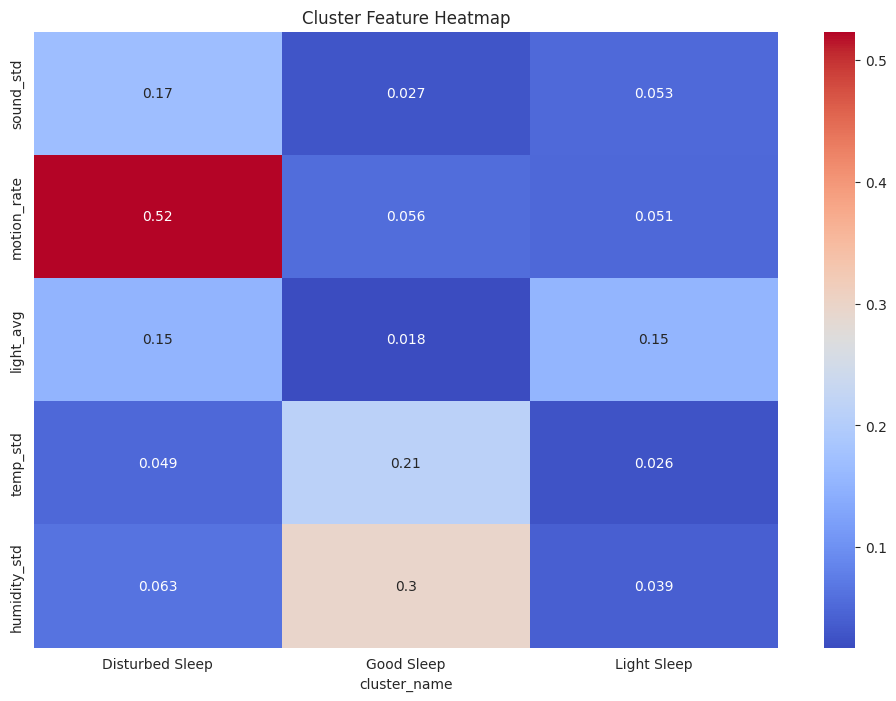

In [16]:
# =========================================================
# Heatmap of cluster feature averages
# =========================================================

cluster_avg = df.groupby('cluster_name')[features].mean()

sns.heatmap(cluster_avg.T, annot=True, cmap='coolwarm')
plt.title("Cluster Feature Heatmap")
plt.savefig("../images/cluster_heatmap.png", dpi=300)
plt.show()

In [17]:
# =========================================================
# Save clustering results
# =========================================================

df.to_csv("../data/cluster_results.csv", index=False)

print("Clustering results saved.")

Clustering results saved.


In [18]:
# =========================================================
# Download all outputs (images + CSV) in Google Colab
# =========================================================

from google.colab import files
import os
import zipfile

# Paths
images_path = "../images"
data_path = "../data"

zip_filename = "sleep_analysis_outputs.zip"

# Create ZIP file
with zipfile.ZipFile(zip_filename, 'w') as zipf:

    # Add images
    if os.path.exists(images_path):
        for file in os.listdir(images_path):
            file_path = os.path.join(images_path, file)
            zipf.write(file_path, arcname=f"images/{file}")

    # Add data files
    if os.path.exists(data_path):
        for file in os.listdir(data_path):
            file_path = os.path.join(data_path, file)
            zipf.write(file_path, arcname=f"data/{file}")

print(" ZIP file created")

# Download ZIP
files.download(zip_filename)

 ZIP file created


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>